Librerias que voy a usar

In [60]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from math import comb

Funcion cargar imagen

In [61]:
def cargarImagen(ruta):
  return cv2.imread(ruta,cv2.IMREAD_GRAYSCALE)

DEFINO TODOS LOS FILTRO QUE VOY A USAR

 - FILTROS PASA BAJOS:

Defino el Kernel Plano

In [62]:
def kernel_plano(filas,columnas):
  kernel=np.ones((filas,columnas))
  suma=np.sum(kernel)
  return kernel/suma
# centro del pixel en una matriz de 2x2 no existe, defino uno

Defino el Kenrnel Barlett

In [63]:
def kernel_bartlett(N):
    mitad = (N // 2) + 1
    seq = np.concatenate((np.arange(1,mitad+1),np.arange(mitad-1,0,-1)))
    kernel = np.outer(seq,seq)
    suma=kernel.sum()

    return kernel/suma

In [64]:
def kernel_gaussiano(N):
    n = N-1
    fila = np.array([comb(n, k) for k in range(N)])
    kernel = np.outer(fila, fila)
    suma= kernel.sum()

    return kernel/suma

- DETECTOR DE BORDES:




In [65]:
def kernel_laplaciano(tipo):
  if tipo== 4:
        kernel = np.array([[0, -1, 0],
                           [-1, 4, -1],
                           [0, -1, 0]], dtype=np.float32)
        return kernel
  elif tipo== 8 :
        kernel = np.array([[-1, -1, -1],
                           [-1, 8, -1],
                           [-1, -1, -1]], dtype=np.float32)
        return kernel
  else:
        raise ValueError("El tipo debe ser 4 o 8. Cualquier otro valor te devuelvo este mensaje devuelta")

In [79]:
def kernel_sobel(num):
    kernels = {
        1: np.array([[-1,  0,  1],
                     [-2,  0,  2],
                     [-1,  0,  1]]),  # 0°

        2: np.array([[ 0,  1,  2],
                     [-1,  0,  1],
                     [-2, -1,  0]]),  # 45°

        3: np.array([[-1, -2, -1],
                     [ 0,  0,  0],
                     [ 1,  2,  1]]),  # 90°

        4: np.array([[-2, -1,  0],
                     [-1,  0,  1],
                     [ 0,  1,  2]]),  # 135°

        5: np.array([[ 1,  0, -1],
                     [ 2,  0, -2],
                     [ 1,  0, -1]]),  # 180°

        6: np.array([[ 0, -1, -2],
                     [ 1,  0, -1],
                     [ 2,  1,  0]]),  # 225°

        7: np.array([[ 1,  2,  1],
                     [ 0,  0,  0],
                     [-1, -2, -1]]),  # 270°

        8: np.array([[ 2,  1,  0],
                     [ 1,  0, -1],
                     [ 0, -1, -2]])   # 315°
    }

    if num not in kernels:
        raise ValueError("El número debe estar entre 1 y 8.")

    return kernels[num]

- FILTRO PASA BANDA Y PASA ALTOS

In [91]:
def kernel_pasaaltos(kernel_pb):
    filas, columnas = kernel_pb.shape
    kernel_delta = np.zeros((filas, columnas))  #matriz de todos ceros
    kernel_delta[filas // 2, columnas // 2] = 1
    kernel_pa = kernel_delta - kernel_pb

    return kernel_pa


def kernel_pasabanda(kernel_pb1, kernel_pb2):
                                                             #el shape devuelve una tupla con (filas, columnas)
    if kernel_pb1.shape != kernel_pb2.shape:                 #Comprueba si los dos kernels no tienen las mismas dimensiones/
        N = max(kernel_pb1.shape[0], kernel_pb2.shape[0])    #Toma el mayor tamaño entre ambos kernels
        kernel_pb1 = np.pad(kernel_pb1, ((0, N - kernel_pb1.shape[0]),(0,N-kernel_pb1.shape[1])), mode='constant') #el pad agrega bordes
        kernel_pb2 = np.pad(kernel_pb2, ((0, N - kernel_pb2.shape[0]),(0,N-kernel_pb2.shape[1])), mode='constant')

    kernel_pb1 =kernel_pb1/np.sum(kernel_pb1)
    kernel_pb2 =kernel_pb2/ np.sum(kernel_pb2)
    kernel_pb = kernel_pb1-kernel_pb2

    return kernel_pb


- FUNCIONES NECESARIAS PARA RECORRER LA MATRIZ CONVOLUCIONADA

In [67]:
def agregar_borde(imagen,cantidadBordes):
  return np.pad(imagen,cantidadBordes,mode='edge')

In [68]:
def multiplicacionKernelImagen(imagen,kernel,fila,columna):
  alto,ancho=kernel.shape
  imagenParcial=imagen[fila-alto//2:fila+alto//2+ 1 ,columna-ancho//2:columna+ancho//2 + 1]

 # Asegurar que coincide en tamaño
  if imagenParcial.shape != kernel.shape:
        return 0
  return np.sum(imagenParcial * kernel)

In [90]:
def aplicar_kernel(imagen, kernel):

    kernelalto, kernelancho = kernel.shape
    imagenPad = agregar_borde(imagen, kernelalto // 2)
    alto, ancho = imagen.shape
    imagenResultante = np.zeros_like(imagen, dtype=np.float32)

    for fila in range(kernelalto // 2, kernelalto // 2 + alto):
        for columna in range(kernelancho // 2, kernelancho // 2 + ancho):
          imagenResultante[fila - kernelalto // 2, columna - kernelancho // 2]=multiplicacionKernelImagen(imagenPad, kernel, fila, columna)



    imagenResultante = np.clip(imagenResultante, 0, 255).astype(np.uint8)
    return imagenResultante


- FUNCION PARA MOSTRAR IMAGEN

In [70]:
def mostrar_imagen(imagen,titulo):
  plt.imshow(imagen,cmap='gray')
  plt.axis('off')
  plt.title(titulo)

#===============================================================================

EMPIEZO A MOSTRAR TODAS LAS IMAGENES

- MOSTRAR IMAGENES

Aplicamos el kernel plano

In [71]:
imagen = cargarImagen('imagen1.jpg')

fila=2
columna=2

miKernel_3 = kernel_plano(3,3)
miKernel_5 = kernel_plano(5,5)
miKernel_7 = kernel_plano(7,7)

imagen_filtrada = aplicar_kernel(imagen, miKernel_3)
imagen_filtrada2 = aplicar_kernel(imagen, miKernel_5)
imagen_filtrada3 = aplicar_kernel(imagen, miKernel_7)


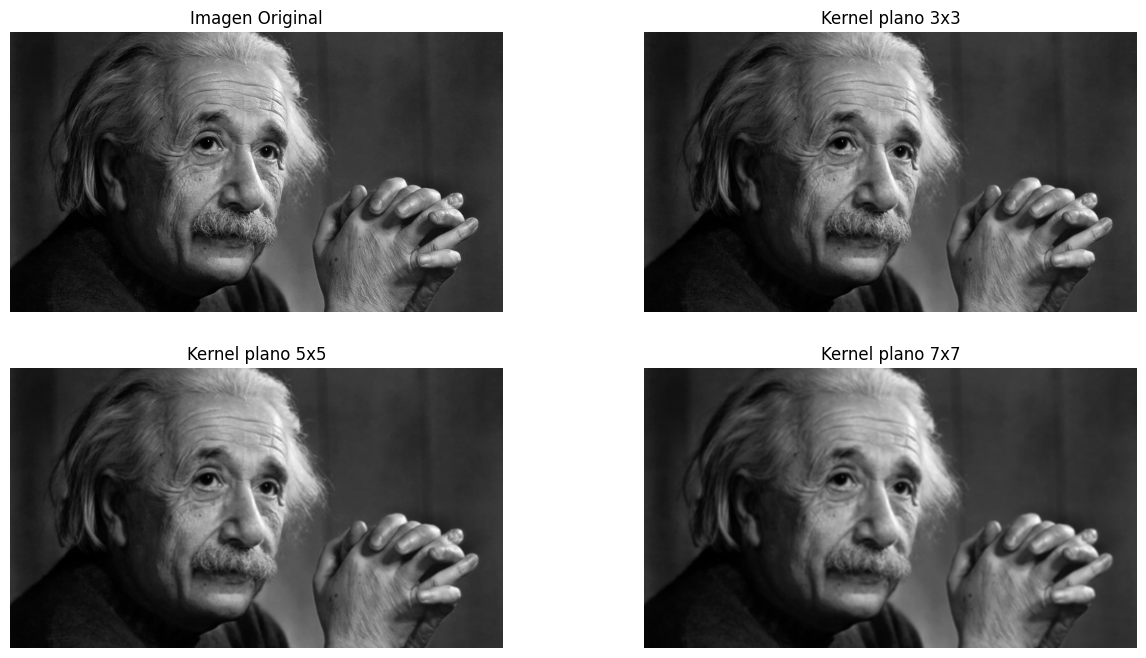

In [72]:
plt.figure(figsize=(15,8))

plt.subplot(fila,columna,1)
mostrar_imagen(imagen, 'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(imagen_filtrada, 'Kernel plano 3x3')

plt.subplot(fila,columna,3)
mostrar_imagen(imagen_filtrada2, 'Kernel plano 5x5')

plt.subplot(fila,columna,4)
mostrar_imagen(imagen_filtrada3, 'Kernel plano 7x7')



Aplicamos el kernel de Bartett

In [73]:
ker_bartlett_1=kernel_bartlett(3)
ker_bartlett_2=kernel_bartlett(5)
ker_bartlett_3=kernel_bartlett(7)

img_bartlett1 = aplicar_kernel(imagen,ker_bartlett_1)
img_bartlett2 = aplicar_kernel(imagen,ker_bartlett_2)
img_bartlett3 = aplicar_kernel(imagen,ker_bartlett_3)


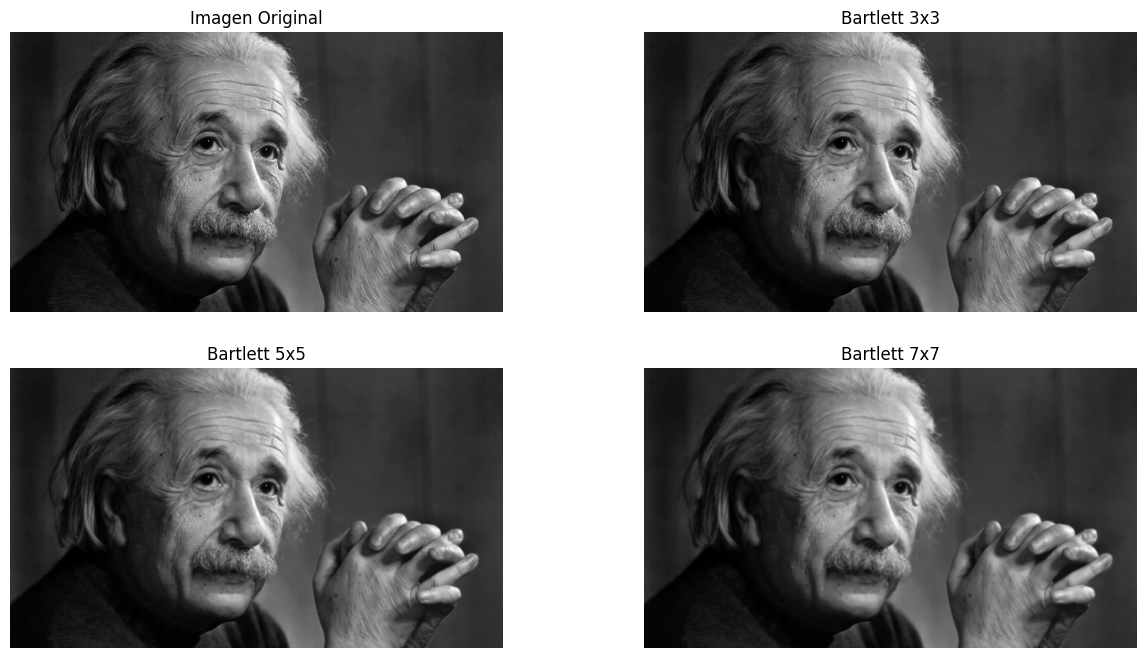

In [74]:
plt.figure(figsize=(15,8))

plt.subplot(fila,columna,1)
mostrar_imagen(imagen, 'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(img_bartlett1, 'Bartlett 3x3')

plt.subplot(fila,columna,3)
mostrar_imagen(img_bartlett2, 'Bartlett 5x5')

plt.subplot(fila,columna,4)
mostrar_imagen(img_bartlett3, 'Bartlett 7x7')



Aplicamos el kernel Gussiano

In [75]:
kernel_gaussiano_5 = kernel_gaussiano(5)
kernel_gaussiano_7 = kernel_gaussiano(7)

img_gaussiano_5 = aplicar_kernel(imagen, kernel_gaussiano_5)
img_gaussiano_7 = aplicar_kernel(imagen, kernel_gaussiano_7)

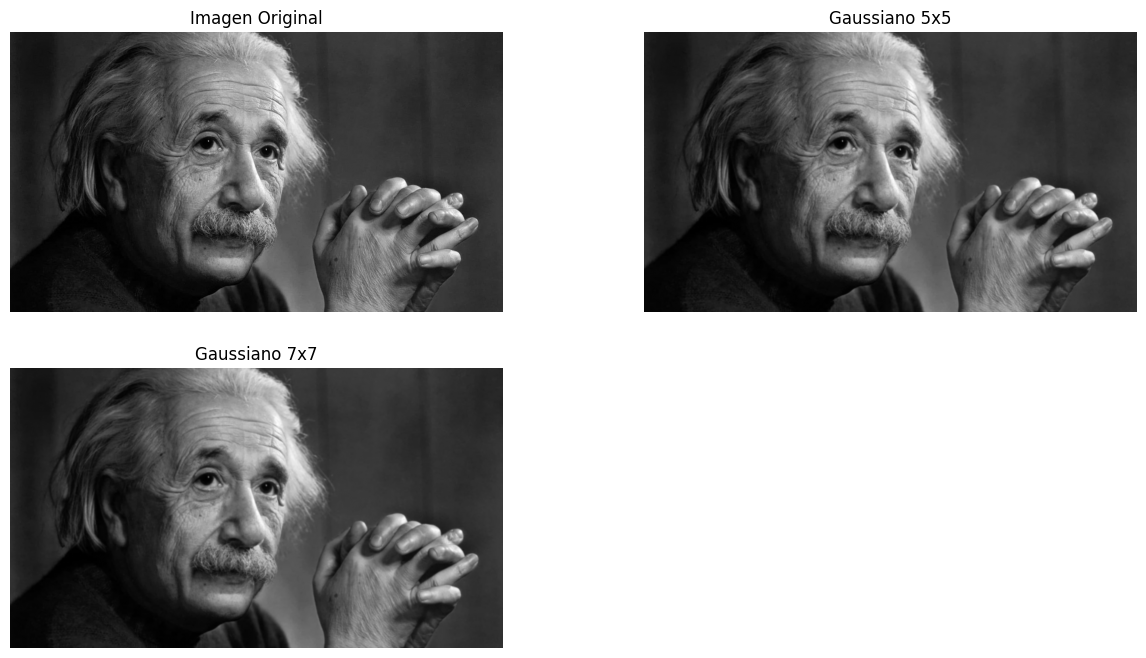

In [76]:
plt.figure(figsize=(15,8))

plt.subplot(2,2,1)
mostrar_imagen(imagen, 'Imagen Original')

plt.subplot(2,2,2)
mostrar_imagen(img_gaussiano_5, 'Gaussiano 5x5')

plt.subplot(2,2,3)
mostrar_imagen(img_gaussiano_7, 'Gaussiano 7x7')






APLICAMOS DETECTOR DE BORDES

Aplicamos Laplaciano v4 y v8

In [77]:
kernel_laplaciano_4 = kernel_laplaciano(4)
kernel_laplaciano_8 = kernel_laplaciano(8)

img_laplaciano_4 = aplicar_kernel(imagen, kernel_laplaciano_4)
img_laplaciano_8 = aplicar_kernel(imagen, kernel_laplaciano_8)

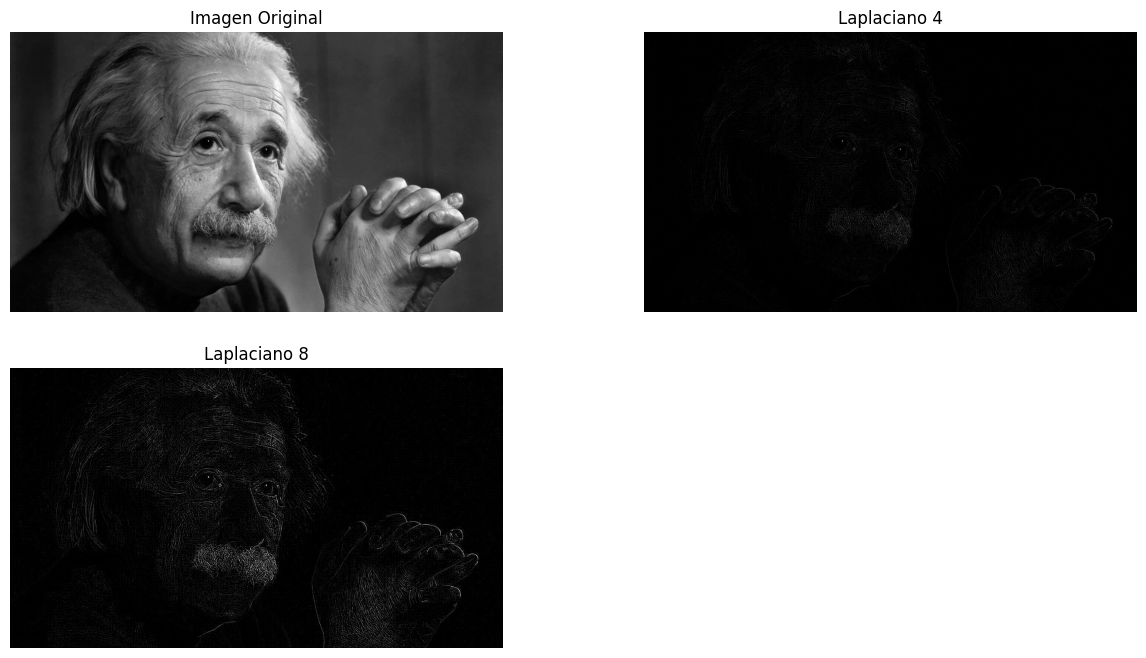

In [78]:
plt.figure(figsize=(15,8))

plt.subplot(fila,columna,1)
mostrar_imagen(imagen, 'Imagen Original')

plt.subplot(fila,columna,2)
mostrar_imagen(img_laplaciano_4, 'Laplaciano 4')

plt.subplot(fila,columna,3)
mostrar_imagen(img_laplaciano_8, 'Laplaciano 8')

Aplicamos Sobel

In [82]:
kernel_sobel_1=kernel_sobel(1)
kernel_sobel_2=kernel_sobel(2)
kernel_sobel_3=kernel_sobel(3)
kernel_sobel_4=kernel_sobel(4)
kernel_sobel_5=kernel_sobel(5)
kernel_sobel_6=kernel_sobel(6)
kernel_sobel_7=kernel_sobel(7)
kernel_sobel_8=kernel_sobel(8)

img_sobel_1=aplicar_kernel(imagen,kernel_sobel_1)
img_sobel_2=aplicar_kernel(imagen,kernel_sobel_2)
img_sobel_3=aplicar_kernel(imagen,kernel_sobel_3)
img_sobel_4=aplicar_kernel(imagen,kernel_sobel_4)
img_sobel_5=aplicar_kernel(imagen,kernel_sobel_5)
img_sobel_6=aplicar_kernel(imagen,kernel_sobel_6)
img_sobel_7=aplicar_kernel(imagen,kernel_sobel_7)
img_sobel_8=aplicar_kernel(imagen,kernel_sobel_8)

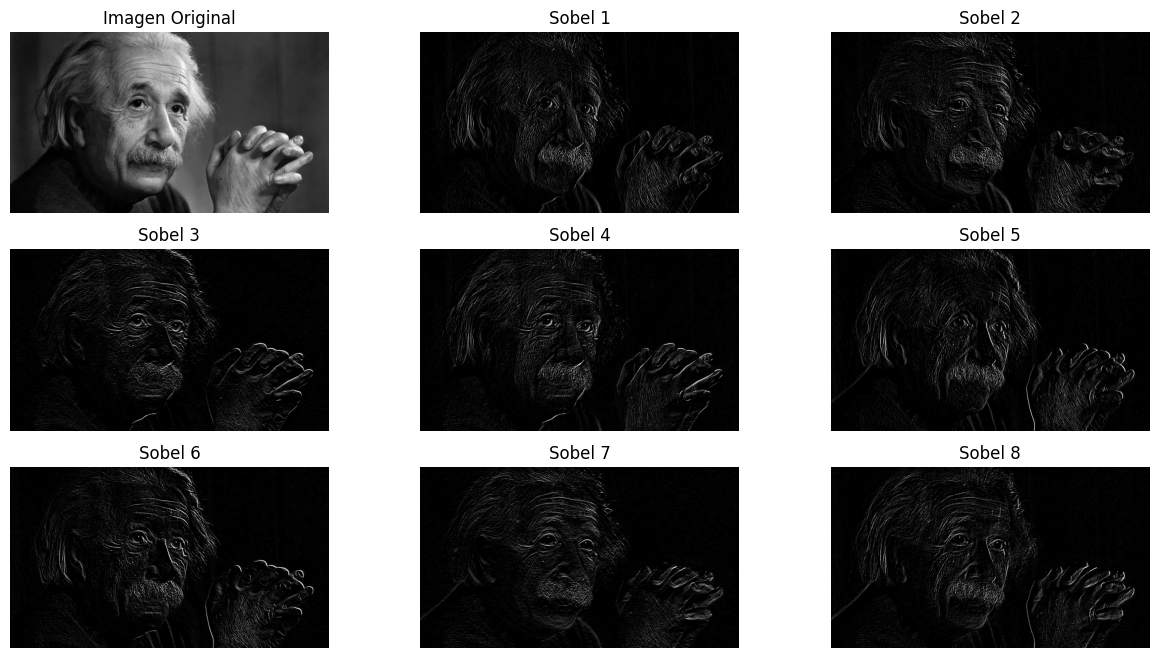

In [83]:
plt.figure(figsize=(15,8))

plt.subplot(3,3,1)
mostrar_imagen(imagen, 'Imagen Original')

plt.subplot(3,3,2)
mostrar_imagen(img_sobel_1,'Sobel 1')

plt.subplot(3,3,3)
mostrar_imagen(img_sobel_2, 'Sobel 2')

plt.subplot(3,3,4)
mostrar_imagen(img_sobel_3, 'Sobel 3')

plt.subplot(3,3,5)
mostrar_imagen(img_sobel_4, 'Sobel 4')

plt.subplot(3,3,6)
mostrar_imagen(img_sobel_5, 'Sobel 5')

plt.subplot(3,3,7)
mostrar_imagen(img_sobel_6, 'Sobel 6')

plt.subplot(3,3,8)
mostrar_imagen(img_sobel_7, 'Sobel 7')

plt.subplot(3,3,9)
mostrar_imagen(img_sobel_8, 'Sobel 8')

In [95]:
kernel_pb3 = kernel_gaussiano(3) # la frecuencia de corte aproxima a 0.33 fc=1/3 para que sea 0.4 la matriz deveria ser de dimension 2.5 , dificil ajaj
kernel_pb5 = kernel_gaussiano(5) # fc=1/5 =0.2
#kernel_pb7 = kernel_gaussiano(7) #la frecuencia de corte aproxima 0.14


kernel_palto = kernel_pasaaltos(kernel_pb3)
kernel_pbanda = kernel_pasabanda(kernel_pb3, kernel_pb5)

imagen_pa = aplicar_kernel(imagen, kernel_palto)
imagen_pbanda = aplicar_kernel(imagen, kernel_pbanda)


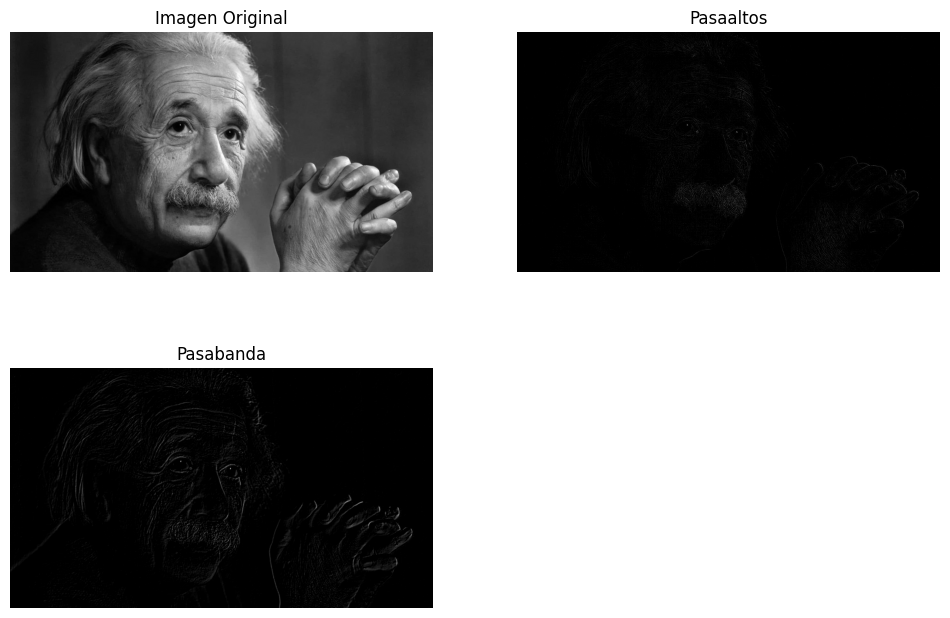

In [96]:
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
mostrar_imagen(imagen, 'Imagen Original')

plt.subplot(2,2,2)
mostrar_imagen(imagen_pa, 'Pasaaltos')

plt.subplot(2,2,3)
mostrar_imagen(imagen_pbanda, 'Pasabanda')
plt.show()
